# ggd_mass model: without vs with Scat4
Same run set-up (M=256, J=8, Q=1+3, seed 900), new (ggd_mass) scalar potentials. Run on Jean Zay (needs `saved_results/`). Built on `run_comparison.py`.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import pandas as pd
from run_comparison import *
pd.set_option('display.float_format', '{:.2f}'.format, 'display.width', 250, 'display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
import numpy as np


In [2]:
RUNS = {   # {display name: --label}; order fixes the colours
    'no Scat4': 'turbulence_ggd_mass_noScat4',
    'with Scat4': 'turbulence_ggd_mass_final',
}
SEED, THRESHOLD = 900, 1e-8
runs, missing = load_runs(RUNS, seed=SEED)
assert not missing, missing
cfg0 = next(iter(runs.values()))['cfg']
x1 = reference_data(cfg0)
xs = {k: r['xt'] for k, r in runs.items()}
print({k: tuple(v.shape) for k, v in xs.items()}, tuple(x1.shape))

{'no Scat4': (10000, 256), 'with Scat4': (10000, 256)} (10000, 256)


## Per-channel table: generated / data (1 = perfect)
m{p} = E|W|^p ratio, q{a} = quantile of |W| ratio. Row j0q0 = finest. `n_series=10000` uses all series (as `compute_marginal_agreement.py`).

In [3]:
N = len(x1)
for bank, J in (('morlet', 8), ('psi', 8)):
    print(f'Q={BANKS[bank]}')
    display(channel_table(x1, xs, bank=bank, J=J, n_series=N))

Q=1


m2                  m4                  m6               q0.99              q0.999             q0.9999           
     no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4
j0q0     0.75       0.92     0.41       0.93     1.00       0.99     1.02       1.02     0.89       0.89     0.64       0.96
j1q0     0.78       0.93     0.36       0.99     0.57       0.90     1.03       1.03     0.88       0.87     0.66       1.00
j2q0     0.88       0.94     0.60       0.98     0.74       0.98     1.03       1.03     0.90       0.89     0.78       1.05
j3q0     0.95       0.96     0.81       0.92     0.96       1.01     1.03       1.02     0.92       0.93     0.84       0.99
j4q0     1.00       1.00     0.99       0.99     1.00       1.01     1.00       1.00     0.98       0.98     0.99       1.01
j5q0     1.00       1.00     1.00       1.00     1.01       1.00     1.00       1.00     1.01       1.00     1.01       1.00
j6q0     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     1.01       1.00
j7q0     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     0.99       0.99     1.02       1.04

Q=3


m2                  m4                  m6               q0.99              q0.999             q0.9999           
     no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4 no Scat4 with Scat4
j0q0     0.98       1.26     0.23       4.89     0.14      13.16     1.01       1.01     1.00       0.98     0.90       0.96
j0q1     0.77       1.12     0.65       5.34     1.01      18.54     1.01       1.01     0.96       0.95     0.64       0.78
j0q2     0.61       0.84     0.33       0.98     0.39       1.07     1.02       1.02     0.92       0.90     0.55       0.73
j1q0     0.48       0.67     0.08       0.18     0.04       0.05     1.02       1.02     0.87       0.87     0.49       0.81
j1q1     0.53       0.92     0.11       0.93     0.07       0.76     1.02       1.02     0.85       0.84     0.49       1.04
j1q2     0.60       1.00     0.14       1.70     0.08       2.27     1.03       1.02     0.85       0.84     0.54       1.08
j2q0     0.71       0.87     0.17       0.73     0.04       0.50     1.02       1.02     0.85       0.85     0.62       0.96
j2q1     0.88       0.96     0.71       1.04     1.02       1.06     1.02       1.02     0.91       0.91     0.83       1.07
j2q2     0.87       0.92     0.90       1.28     1.99       2.74     1.03       1.03     0.93       0.94     0.85       1.04
j3q0     0.90       0.91     0.80       0.88     0.76       0.87     1.02       1.01     0.95       0.96     0.86       0.95
j3q1     0.93       0.94     0.85       0.96     0.65       0.99     1.02       1.01     0.96       0.97     0.91       1.00
j3q2     0.98       0.99     0.89       0.92     0.63       0.75     1.01       1.01     0.98       0.98     0.92       0.96
j4q0     1.00       1.00     1.03       1.03     1.19       1.15     1.00       1.00     0.99       0.99     1.05       1.04
j4q1     1.01       1.01     1.04       1.03     1.11       1.05     1.00       1.00     1.01       1.01     1.04       1.02
j4q2     1.00       1.00     1.01       1.02     1.03       1.09     1.00       1.00     1.00       1.00     1.02       1.05
j5q0     1.00       1.00     1.00       0.98     0.98       0.89     1.00       1.00     1.00       1.00     0.98       0.96
j5q1     1.00       1.00     1.01       0.99     1.07       0.93     1.00       1.01     0.98       0.98     1.12       1.01
j5q2     1.00       1.00     1.00       1.00     1.03       0.99     1.00       1.00     1.00       1.00     1.00       1.00
j6q0     1.00       1.00     0.99       0.99     0.97       0.94     1.00       1.00     1.01       1.01     0.96       0.93
j6q1     1.00       1.00     0.99       0.99     0.98       0.97     1.00       1.00     0.99       1.00     0.99       0.96
j6q2     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     0.99       0.99     1.02       1.04
j7q0     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     0.99       0.99     1.02       1.04
j7q1     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     0.99       0.99     1.02       1.04
j7q2     1.00       1.00     1.00       1.00     1.00       1.00     1.00       1.00     0.99       0.99     1.02       1.04

## Tails per channel (Q=1 then Q=3): histogram and survival function

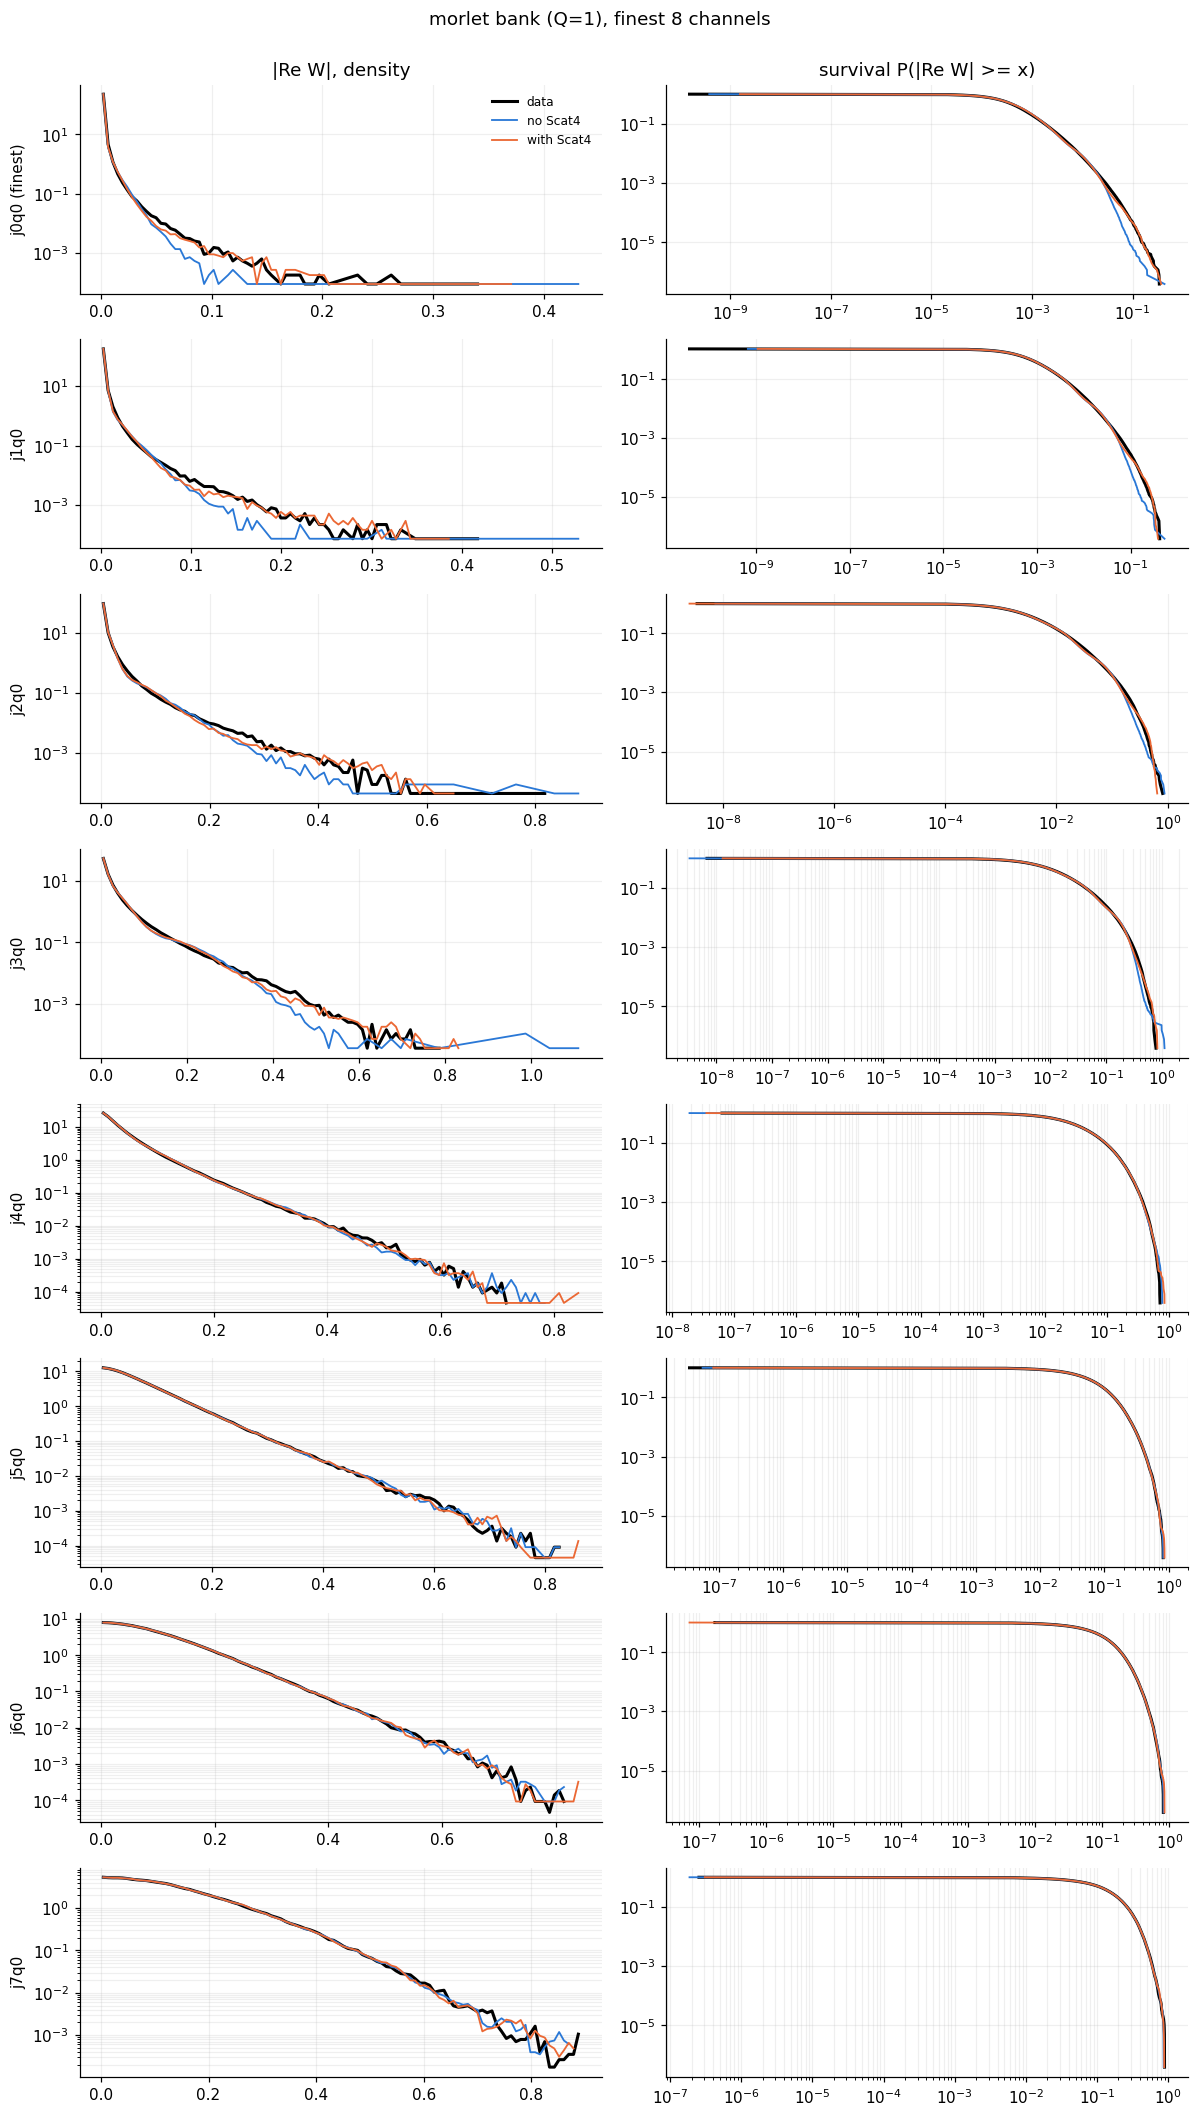

In [4]:
plot_tail_hists(x1, xs, bank='morlet', n_ch=8, n_series=N)

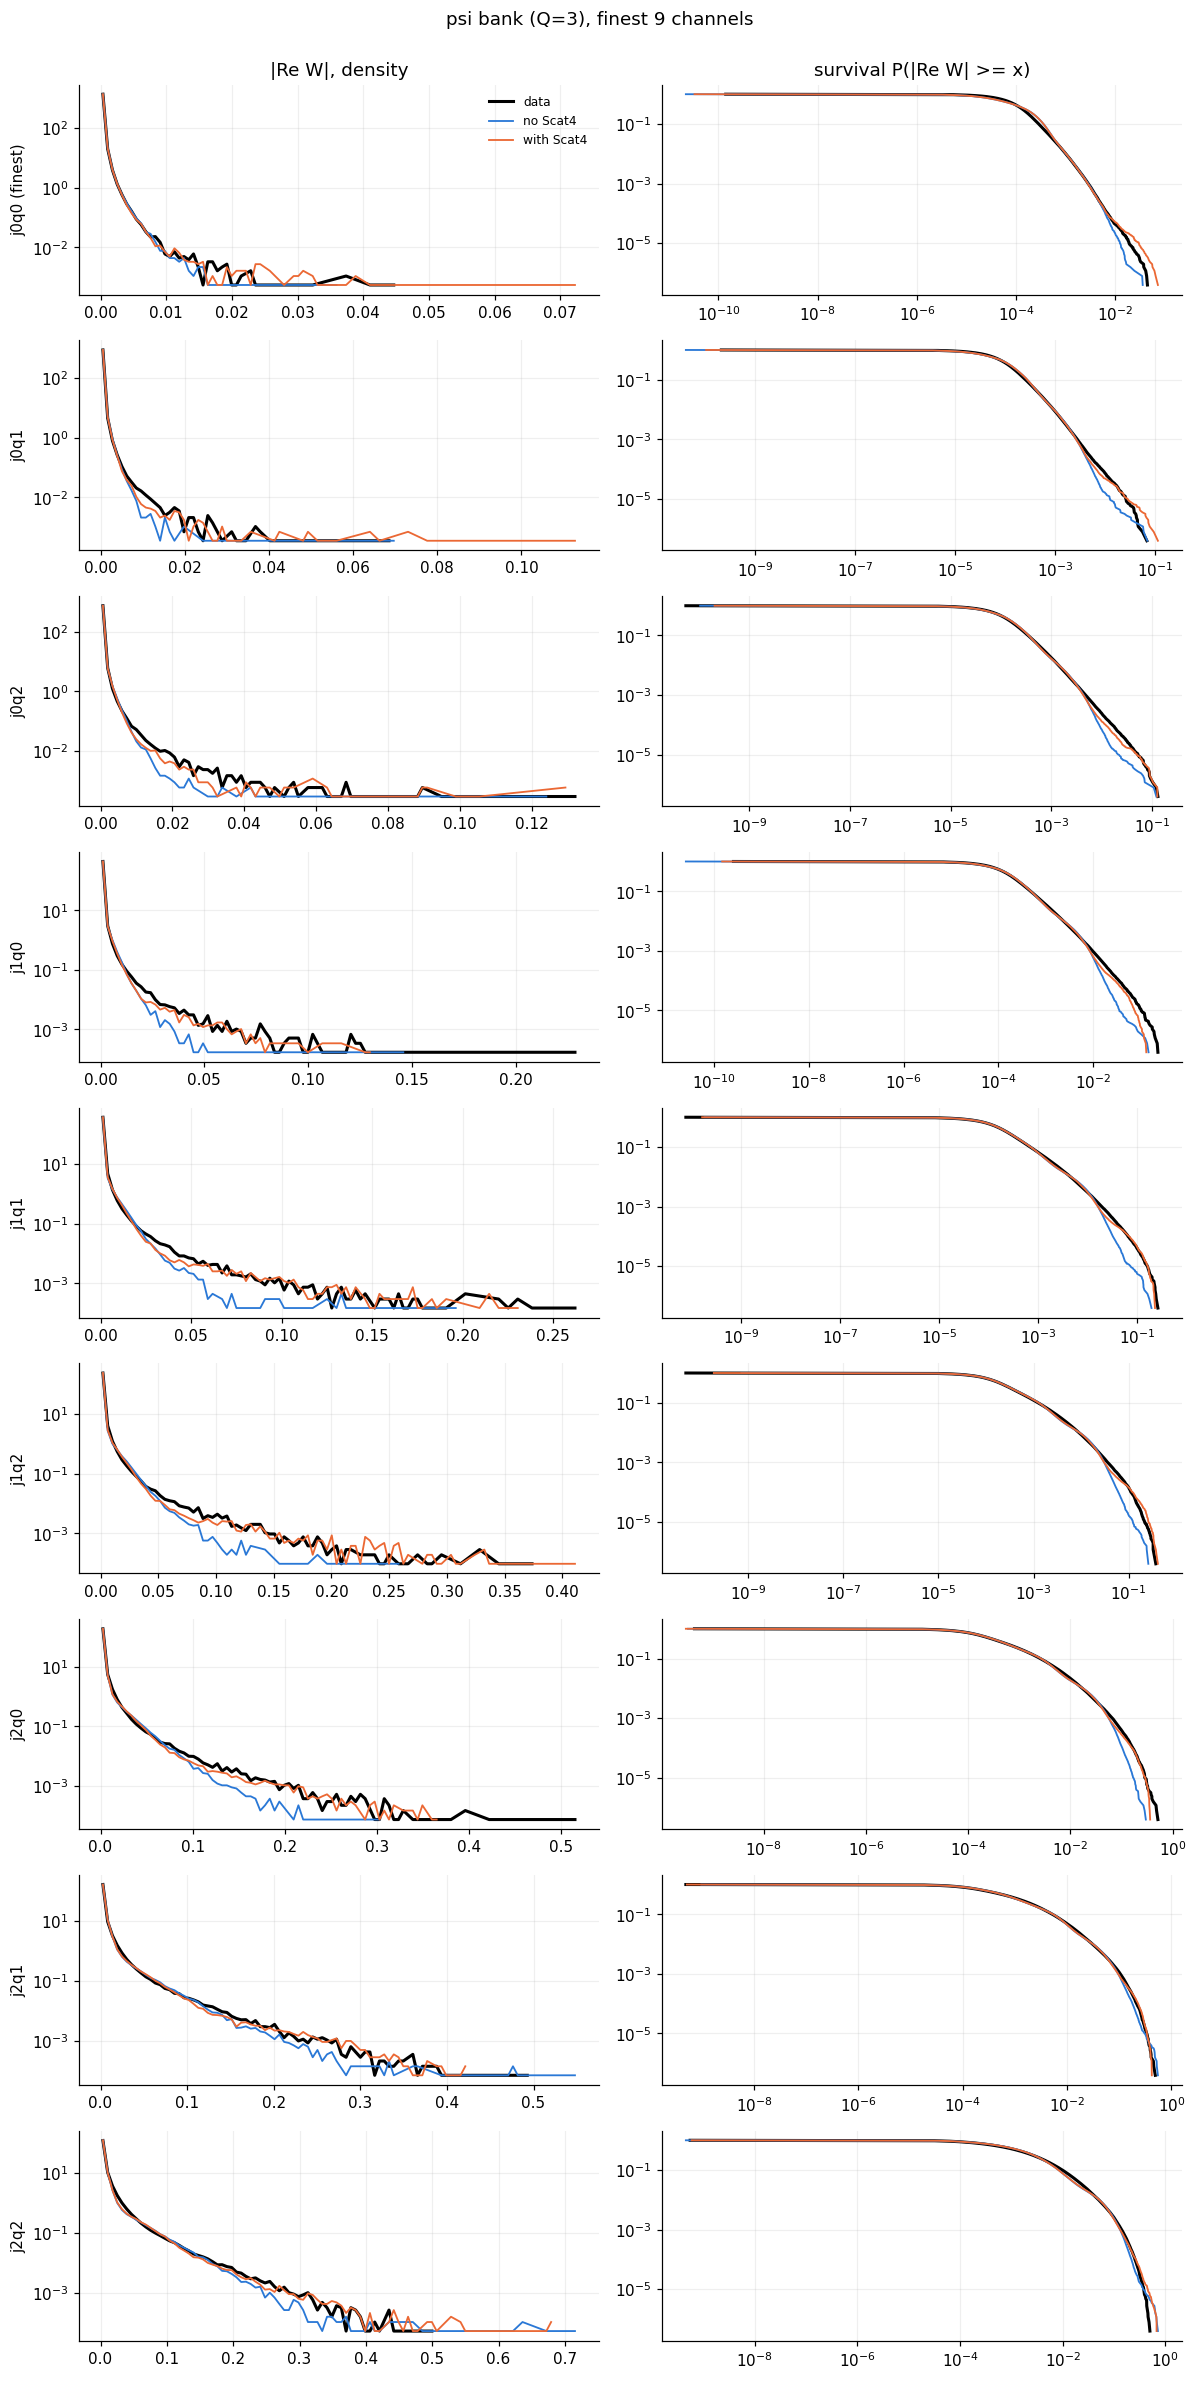

In [5]:
plot_tail_hists(x1, xs, bank='psi', n_ch=9, n_series=N)

## Statistics
Physical statistics, then the imposed moments at the end of the run (the two runs have different potential sets, so only the error distributions are comparable).

In [6]:
S_ref = compute_stats(x1)
S_runs = {k: compute_stats(v) for k, v in xs.items()}
ks = wavelet_ks(S_ref, S_runs)
summary_table(S_ref, S_runs, runs, THRESHOLD, ks=ks)

,reg,sched,n_terms,nt,n1,runtime_h,mm_final_median,mm_final_p90,mm_final_max,mm_n_above_1pct,S2_ratio_tau1,flat4_ratio_tau1,flat6_ratio_tau1,skew_tau1 (data 0.018),spec_logrms,spec_logrms_oct,wav_E_logrms,wav_flat_logrms,marg_KS,wav_KS_max
no Scat4,0.00,2.00,3.00,55000.00,10000.00,4.20,0.00,0.00,0.25,10.00,0.93,0.86,2.99,0.08,0.42,0.32,0.31,0.60,0.02,0.08
with Scat4,0.00,2.00,5.00,55000.00,10000.00,18.20,0.00,0.00,0.25,10.00,0.97,1.06,1.21,0.04,0.23,0.15,0.13,0.51,0.02,0.09


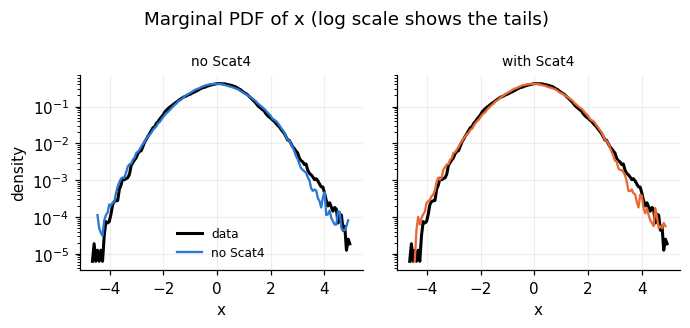

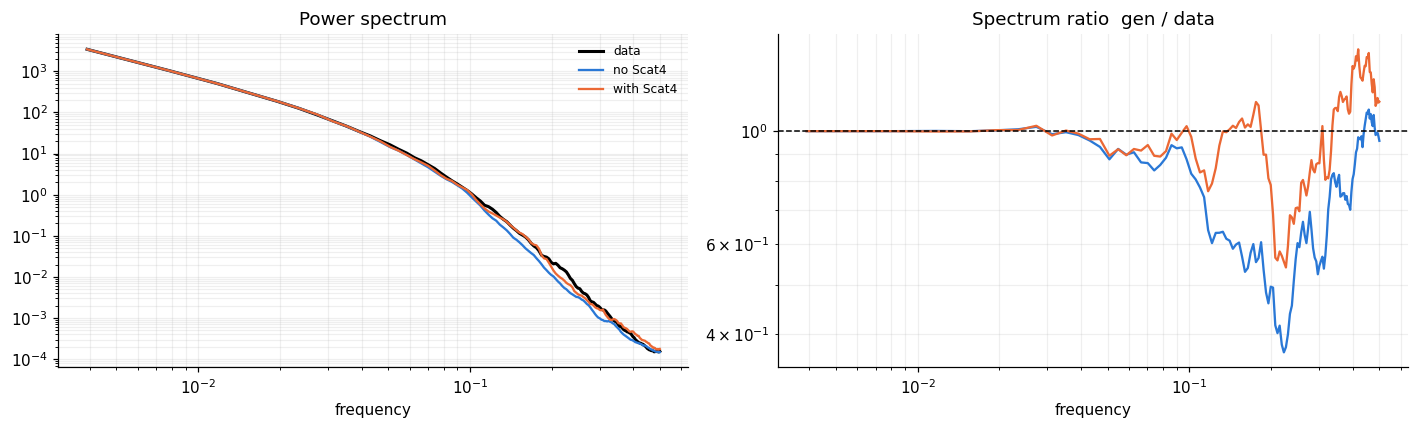

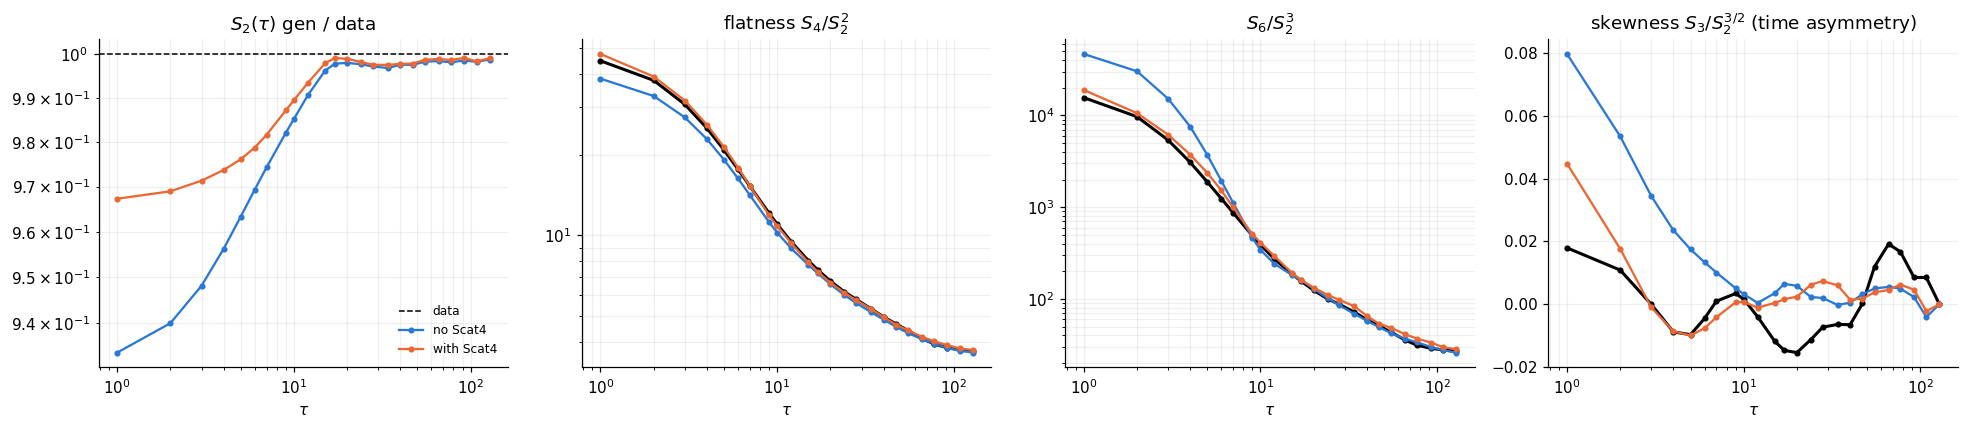

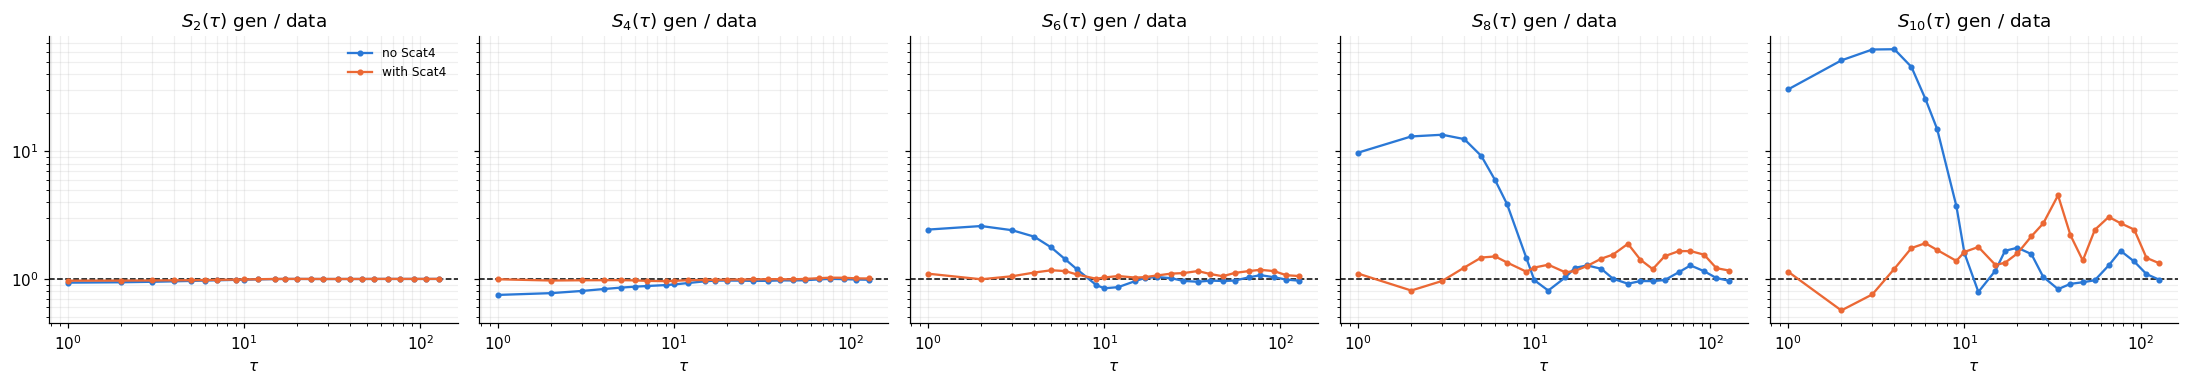

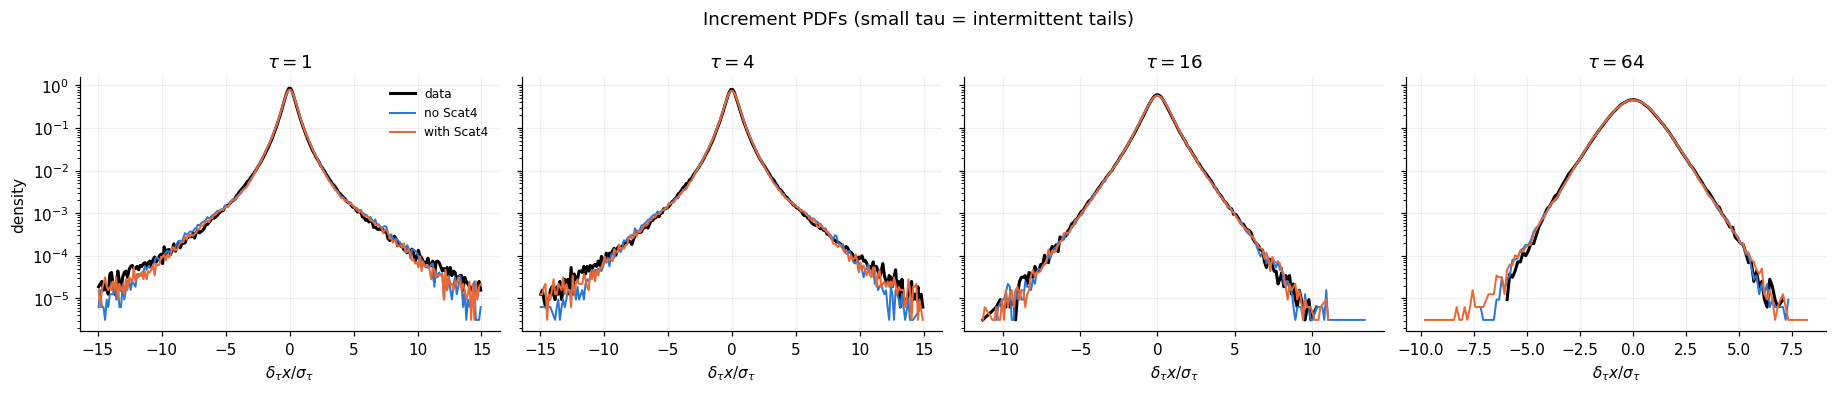

In [7]:
plot_marginals(S_ref, S_runs); plot_spectra(S_ref, S_runs); plot_structure(S_ref, S_runs); plot_structure_orders(S_ref, S_runs); plot_increment_pdfs(S_ref, S_runs)

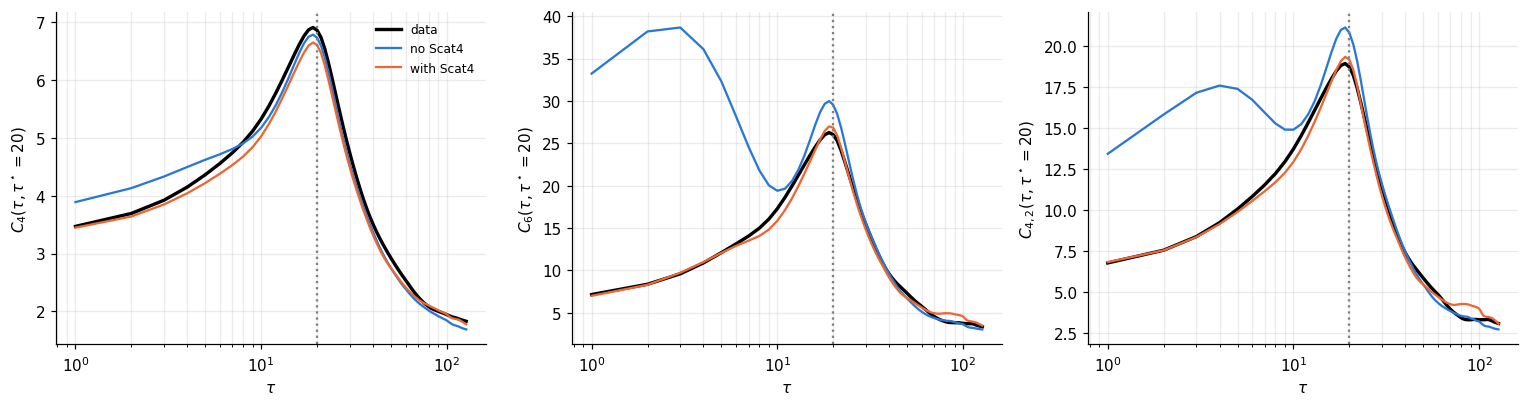

In [17]:
# --- across-scale statistics C_{p,q}(tau, tau*) = E[|du_tau*|^p |du_tau|^q] / (S_p(tau*) S_q(tau)),  as the paper's panels f, g, h ---
from check_moments import C_pq_structure           # codes/check_moments.py (the paper figures use the same function)

TAU_STAR, N_SERIES = 20, 5000                       # N_SERIES: random subset, 5000 is plenty and keeps it fast
panels = [((2, 2), r'$C_4$'), ((3, 3), r'$C_6$'), ((4, 2), r'$C_{4,2}$')]
rng = np.random.default_rng(0)
pick = lambda x: np.asarray(x)[rng.choice(len(x), min(N_SERIES, len(x)), replace=False)].astype(float)
sources = {'data': pick(x1.numpy() if hasattr(x1, 'numpy') else x1)}
sources.update({k: pick(v.numpy() if hasattr(v, 'numpy') else v) for k, v in xs.items()})

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, ((p, q), title) in zip(axes, panels):
    for i, (name, x) in enumerate(sources.items()):
        taus, r = C_pq_structure(x, p, q, TAU_STAR, max_tau=x.shape[-1] // 2)
        ax.plot(taus, r, color='black' if name == 'data' else PALETTE[(i - 1) % len(PALETTE)],
                lw=2.2 if name == 'data' else 1.5, label=name)
    ax.axvline(TAU_STAR, color='gray', ls=':', lw=1.5)
    ax.set_xscale('log'); ax.set_xlabel(r'$\tau$'); ax.set_ylabel(rf'{title}$(\tau, \tau^\star={TAU_STAR})$')
    ax.grid(alpha=0.25, which='both')
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()

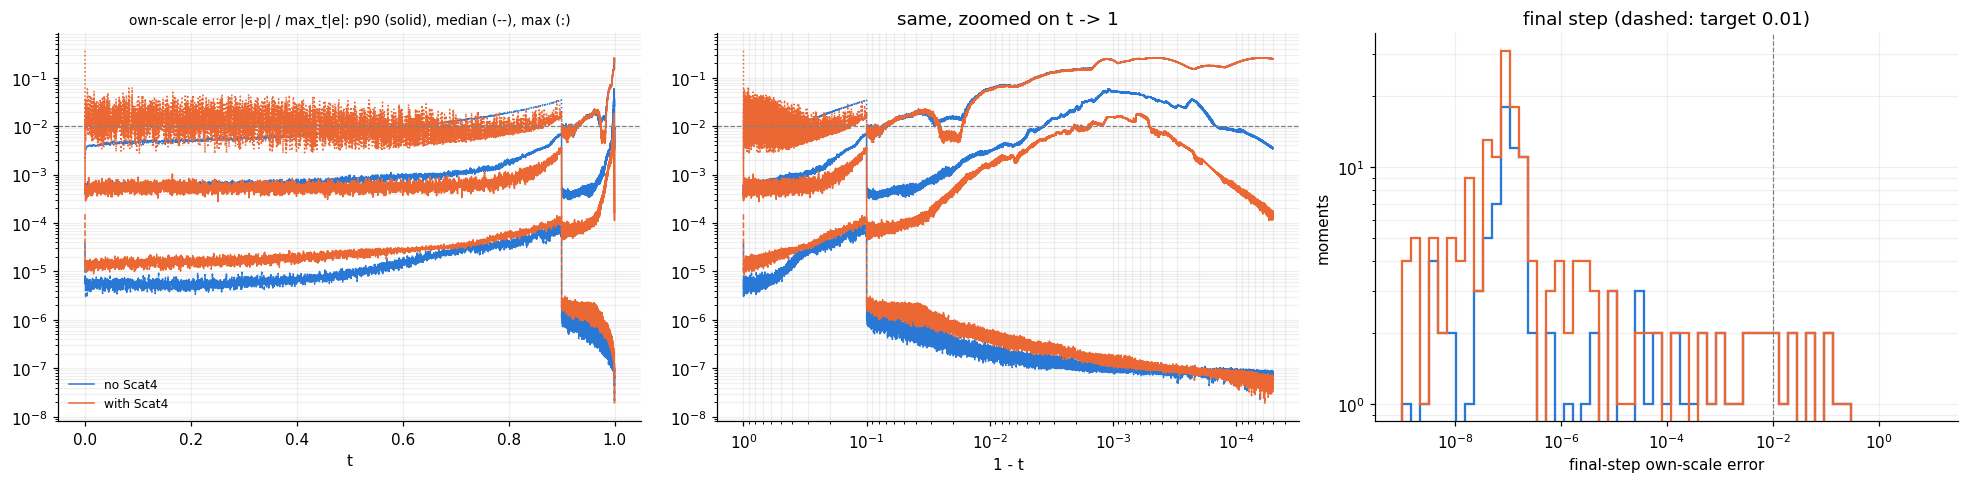

In [8]:
plot_moment_matching(runs, THRESHOLD)

## log p (read from `logp_family_contrib.py` outputs)
Overall log p of all signals (gray) with rare / typical outlines on a common x-axis, then the per-family contribution (mean and std). Rare = top 5% of max |lag-1 increment|. Needs `figures/data/logp_C_<label>_lam<lam>_unc.npz` for both runs.

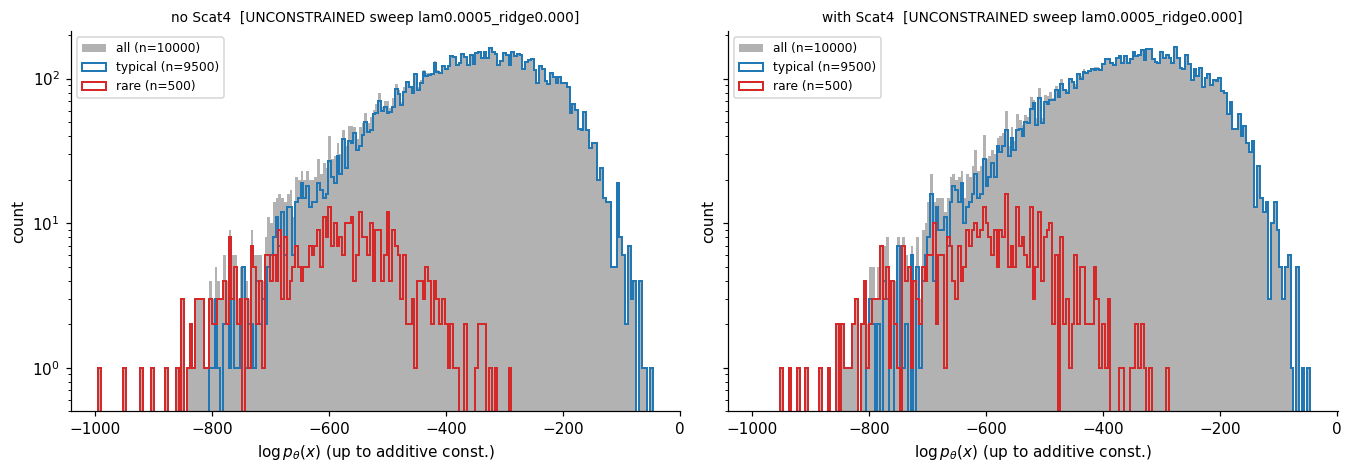

In [13]:
import plot_logp_summary as pl
LP = {'no Scat4': 'turbulence_ggd_mass_noScat4', 'with Scat4': 'turbulence_ggd_mass_final'}
LAM, SUFFIX, P = 5e-4, '_unc', 95
data = {k: pl.load(l, LAM, SUFFIX) for k, l in LP.items()}
edges = np.linspace(min(C['TOTAL'].min() for C, _, _ in data.values()),
                    max(C['TOTAL'].max() for C, _, _ in data.values()), 201)
fig, axes = plt.subplots(1, len(data), figsize=(6.2 * len(data), 4.4), sharex=True, sharey=True)
for ax, (k, (C, inc, desc)) in zip(axes, data.items()):
    pl.plot_aggregate(ax, C, pl.rare_mask(inc, P), edges, f'{k}  [{desc[:40]}]')
fig.tight_layout(); plt.show()

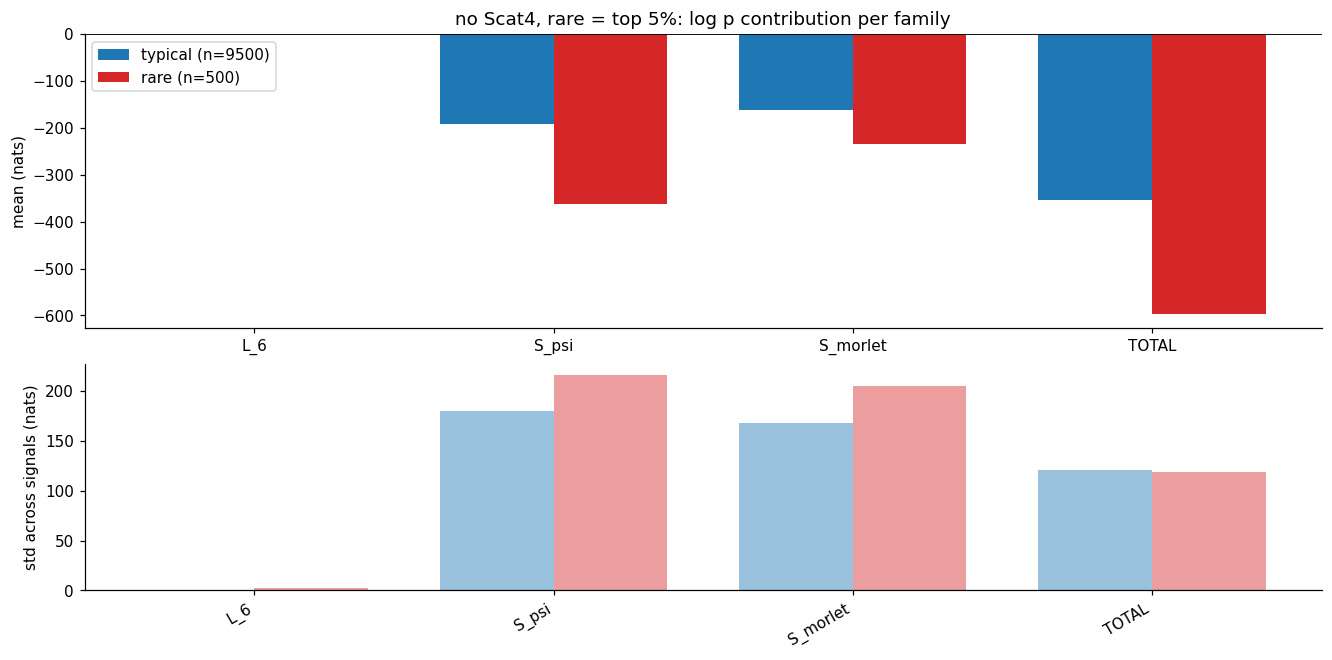

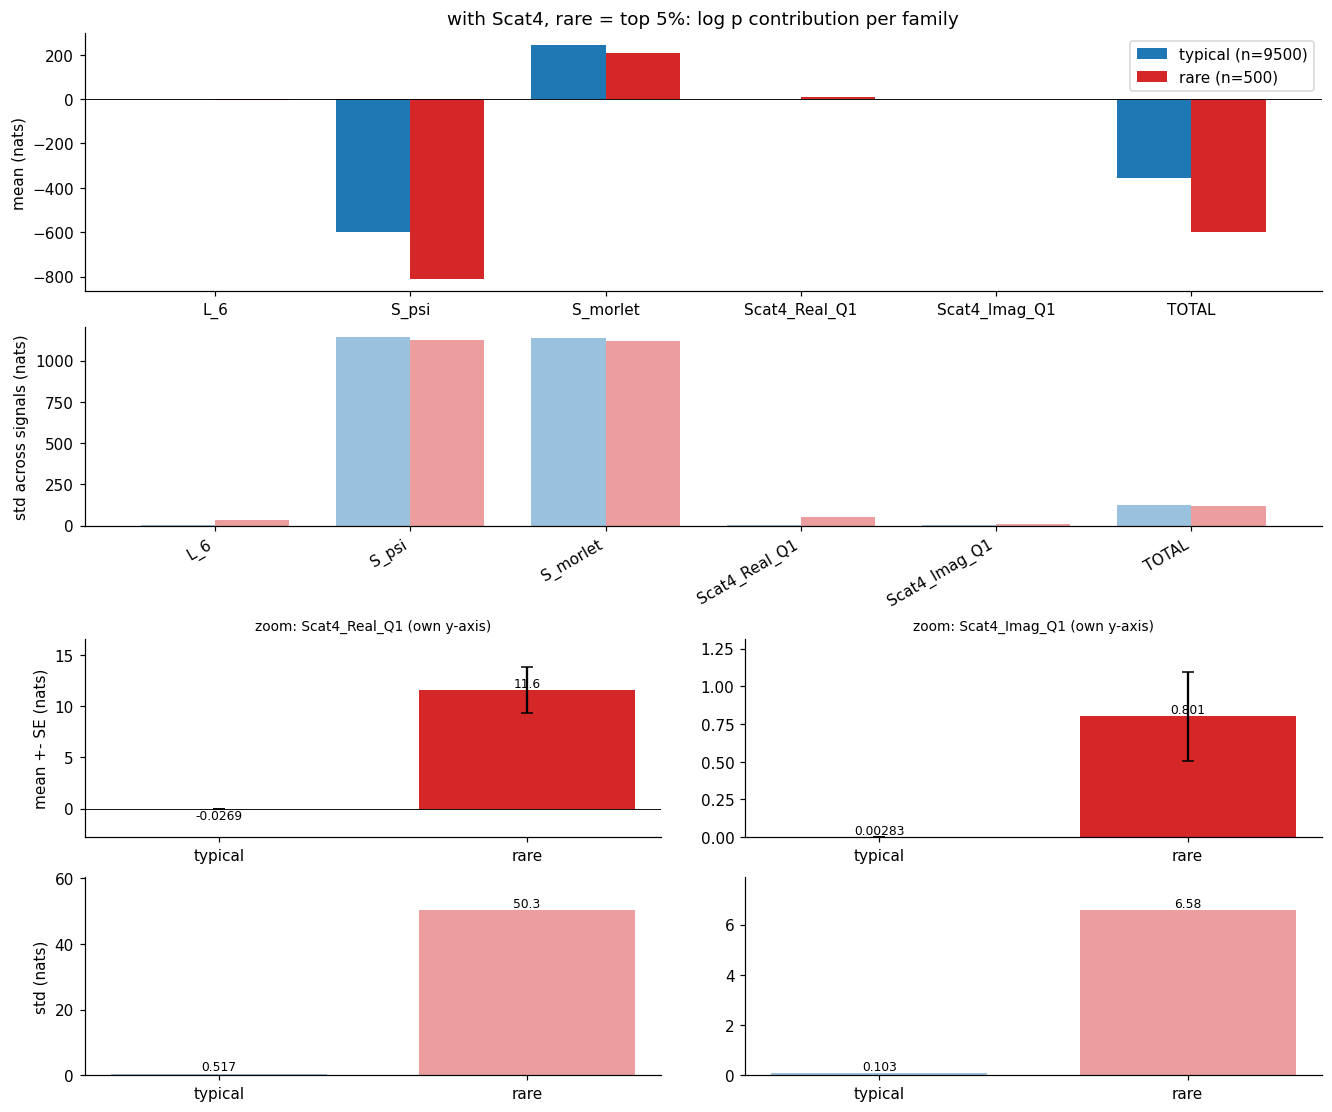

In [14]:
for k, (C, inc, desc) in data.items():
    pl.plot_bars(C, pl.rare_mask(inc, P), f'{k}, rare = top {100 - P:g}%'); plt.show()

threshold 15.0 sigma_tau (data p99), tau=1
  data           100 / 10000 rare series (1.00%)
  no Scat4        29 / 10000 rare series (0.29%)
  with Scat4      63 / 10000 rare series (0.63%)
data strongest rare series: [4592, 4578, 4572, 3341]  scores: [40.70000076293945, 36.599998474121094, 36.400001525878906, 32.79999923706055]


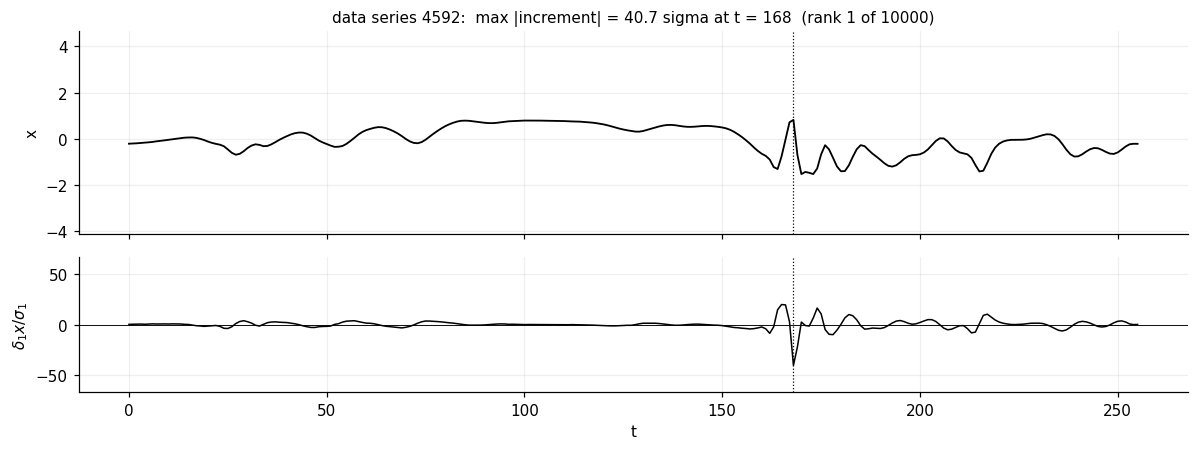

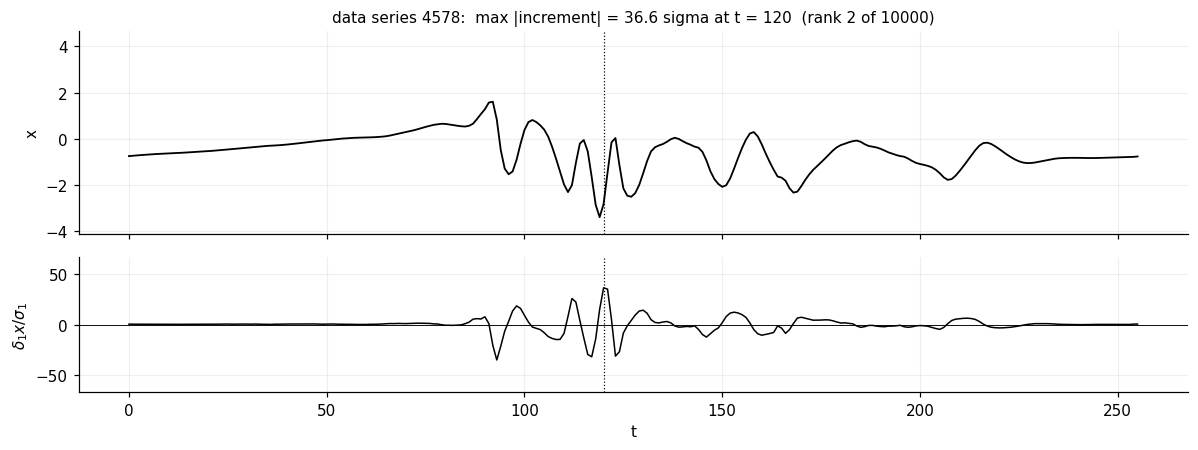

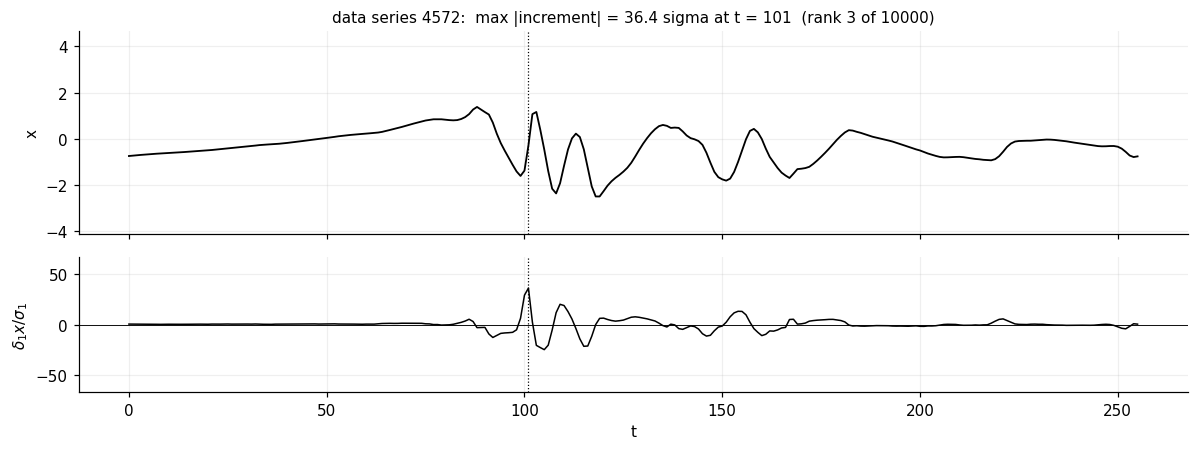

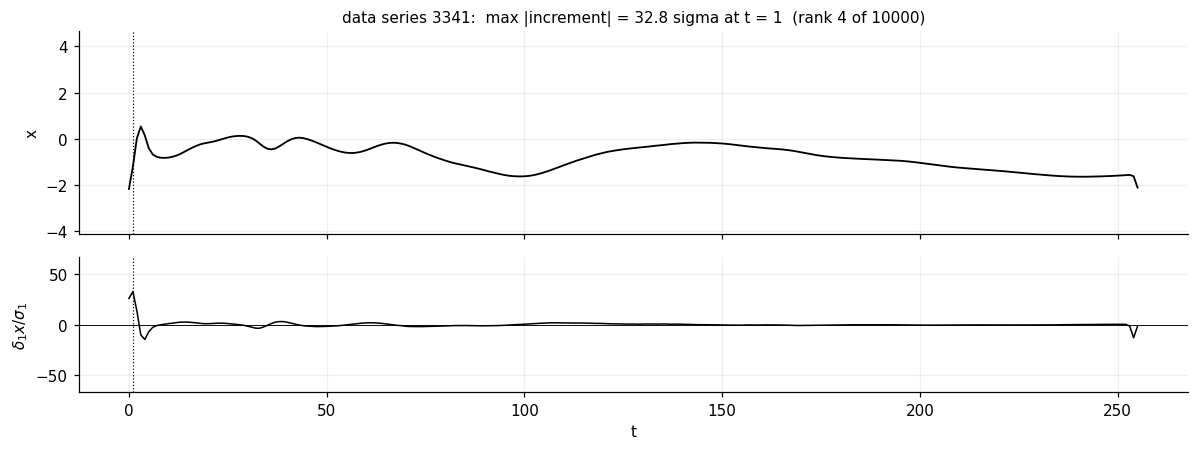

no Scat4 strongest rare series: [6298, 2522, 4355, 5138]  scores: [61.29999923706055, 34.29999923706055, 26.700000762939453, 22.200000762939453]


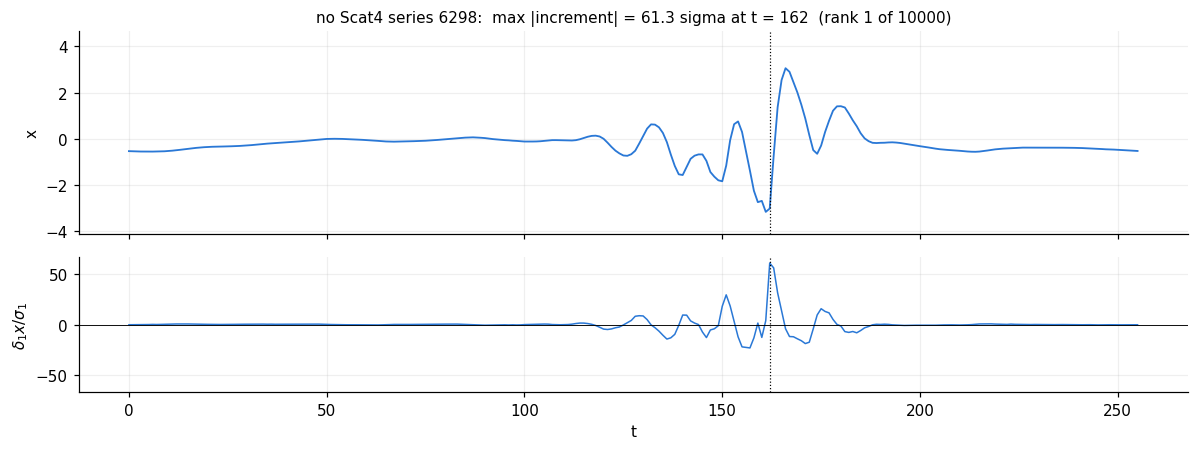

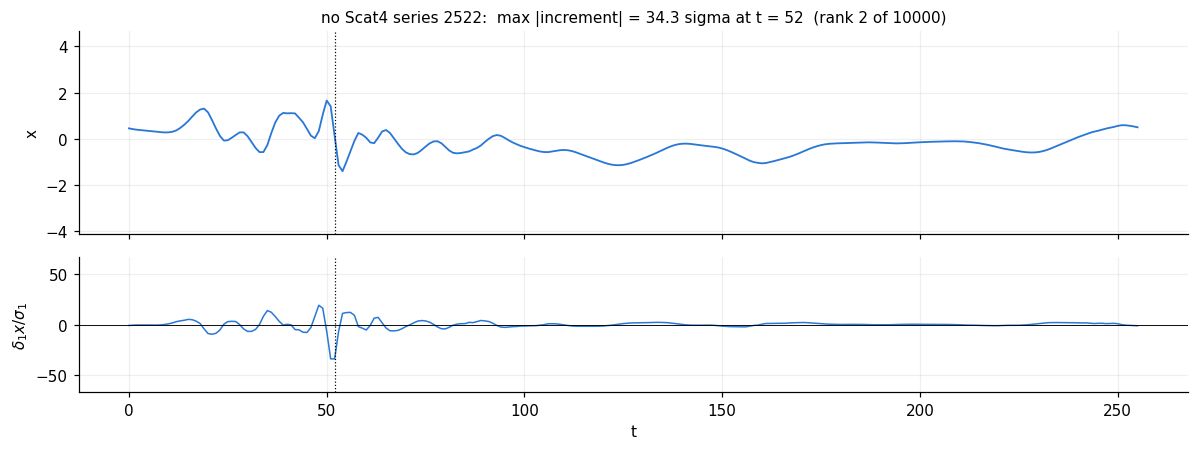

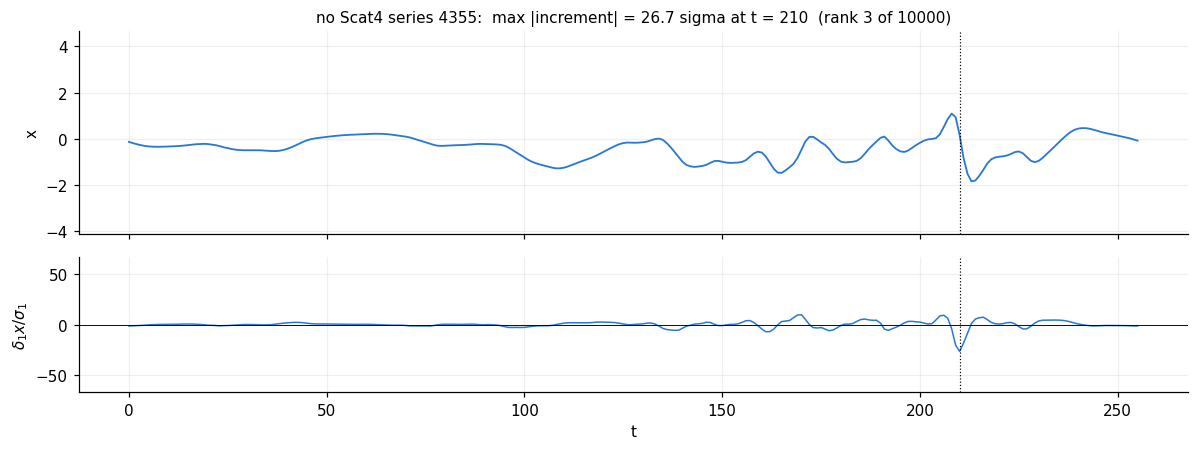

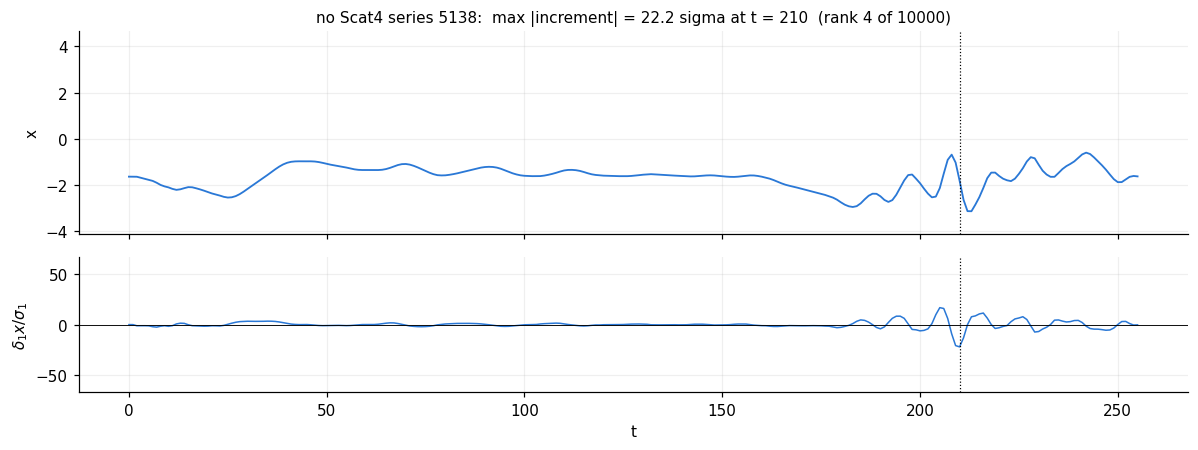

with Scat4 strongest rare series: [5366, 8730, 8388, 7571]  scores: [43.29999923706055, 36.599998474121094, 31.200000762939453, 30.100000381469727]


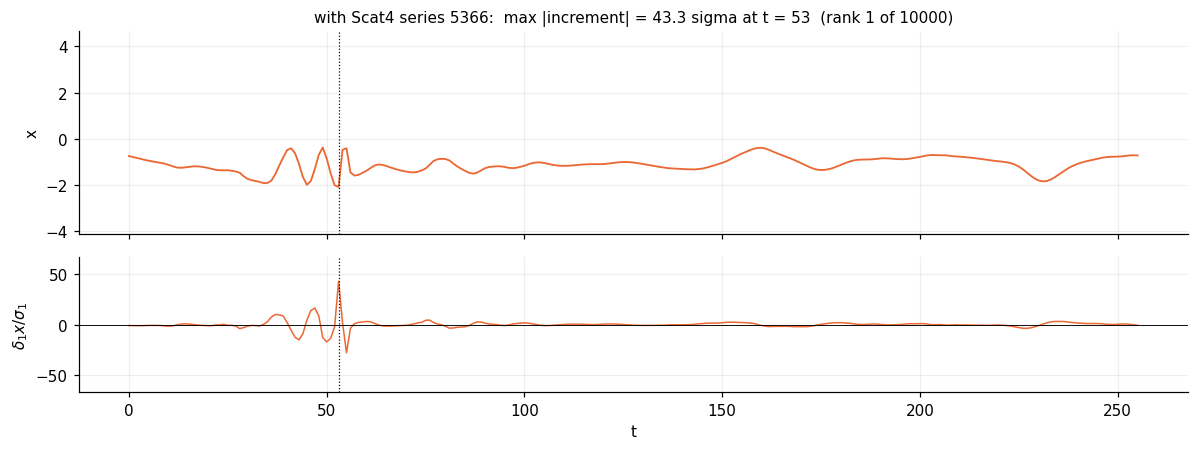

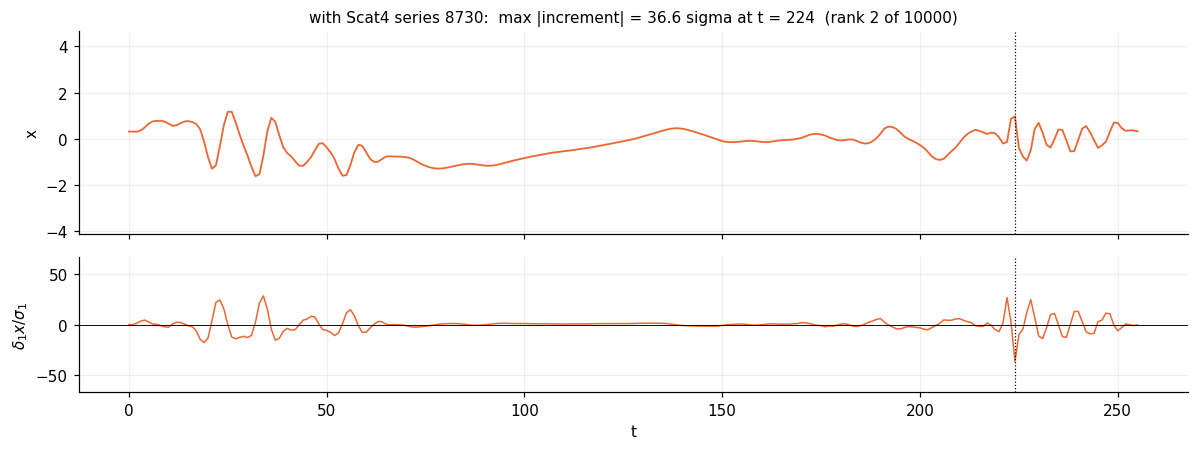

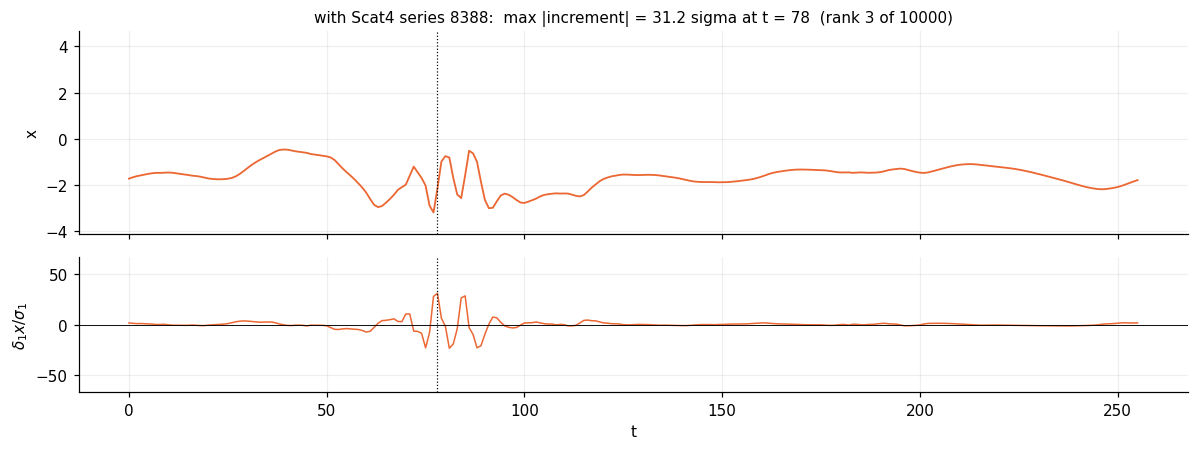

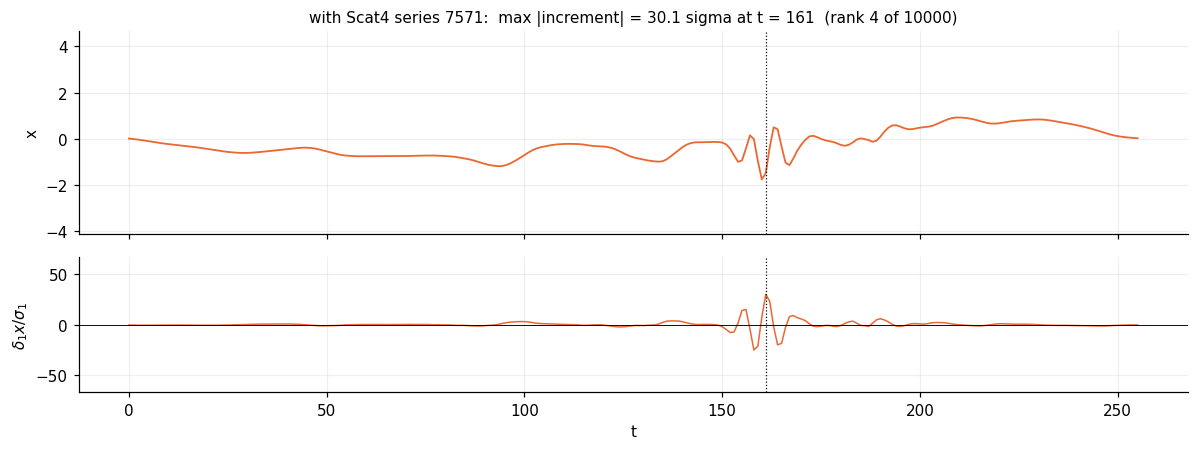

In [16]:
# --- rare events: generated series that contain one, selected with the DATA's criterion ---
TAU, PCT, N_SHOW = 1, 99, 4          # rare = largest |lag-TAU increment| above the PCT-th percentile of the data's scores

s_data, _, _ = event_scores(x1, TAU)                       # scores in units of the data's own sigma_tau
thr = np.percentile(s_data, PCT)
scores = {'data': s_data}
for name, x in xs.items():
    scores[name] = event_scores(x, TAU, ref=x1)[0]         # same sigma_tau (the data's) for every source
rare = {k: np.flatnonzero(s > thr) for k, s in scores.items()}
print(f'threshold {thr:.1f} sigma_tau (data p{PCT}), tau={TAU}')
for k, v in rare.items():
    print(f'  {k:12s} {len(v):5d} / {len(scores[k])} rare series ({100 * len(v) / len(scores[k]):.2f}%)')

# the rare series themselves, strongest first, on the same axes for every source
ylim = (np.percentile(x1, 0.001), np.percentile(x1, 99.999))
inc_ylim = (-1.1 * max(s.max() for s in scores.values()), 1.1 * max(s.max() for s in scores.values()))
rare_idx = {}
for i, (name, x) in enumerate([('data', x1)] + list(xs.items())):
    idx = rare[name][np.argsort(-scores[name][rare[name]])][:N_SHOW]
    rare_idx[name] = idx
    print(name, 'strongest rare series:', idx.tolist(), ' scores:', np.round(scores[name][idx], 1).tolist())
    plot_series(x, idx=idx, tau=TAU, ref=x1, name=name, color='black' if name == 'data' else PALETTE[(i - 1) % len(PALETTE)],
                ylim=ylim, inc_ylim=inc_ylim)